<a href="https://colab.research.google.com/github/Nafimunnisa/nafimunnisa-2026/blob/main/Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [6]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target
df["species"] = df["species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})

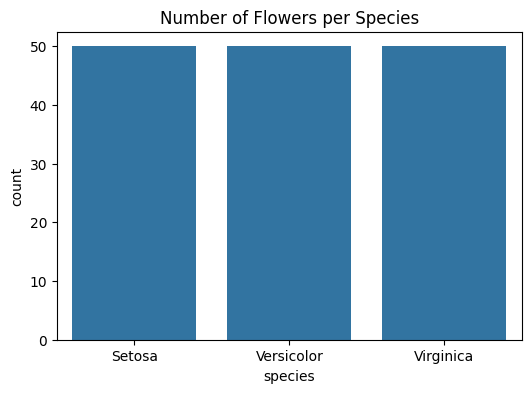

In [7]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="species")

plt.title("Number of Flowers per Species")
plt.show()

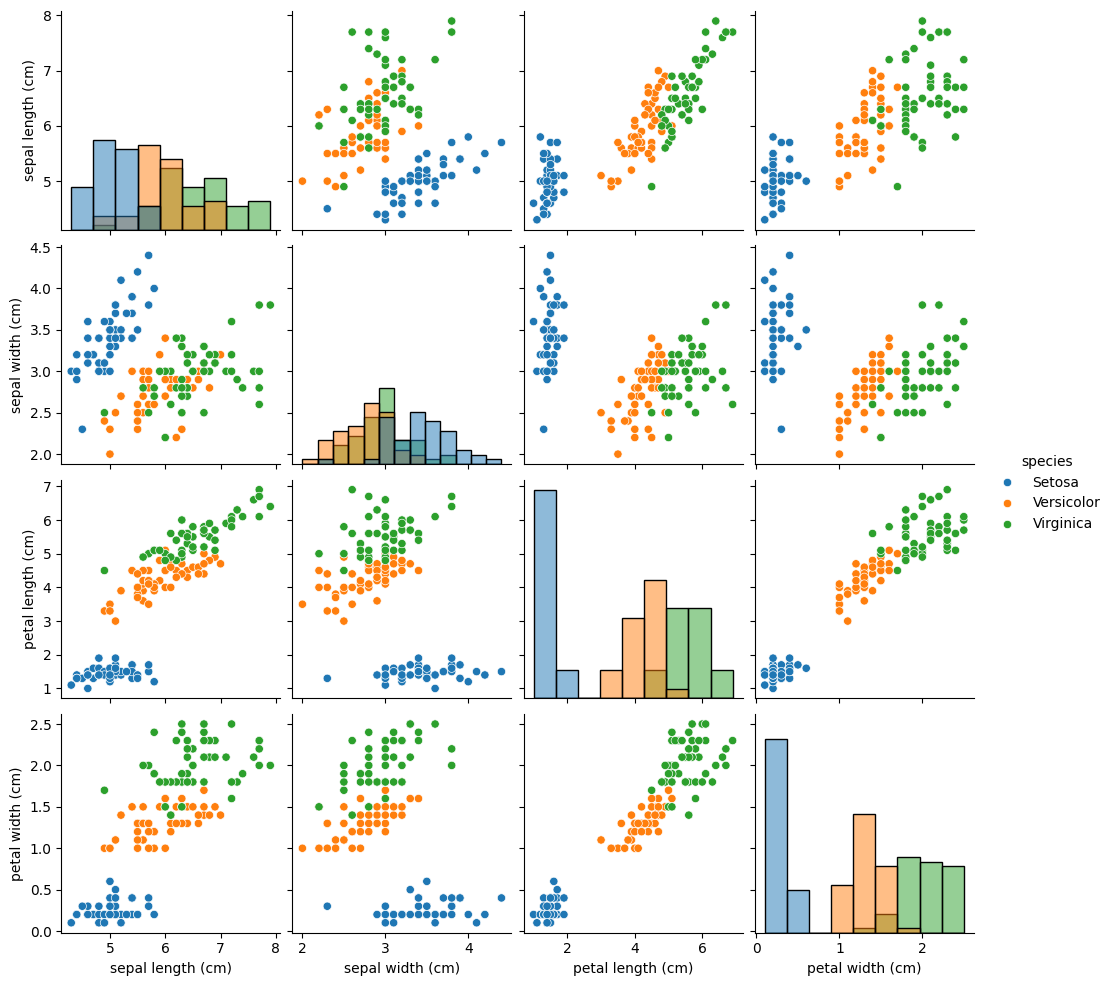

In [8]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

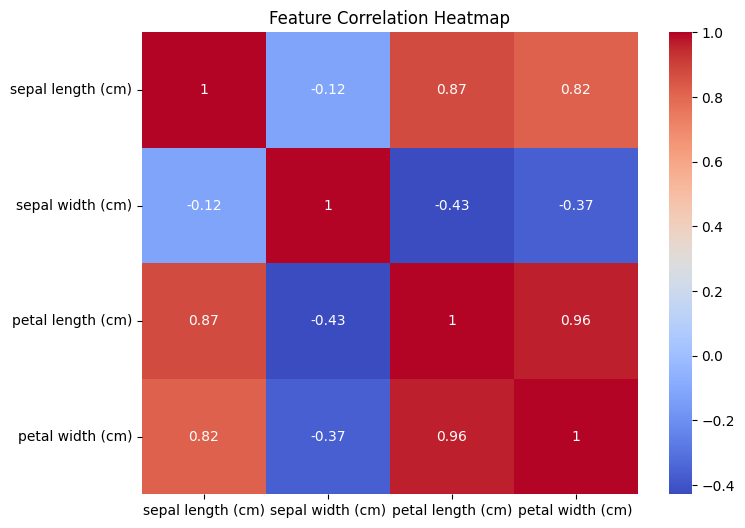

In [9]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.drop("species", axis=1).corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

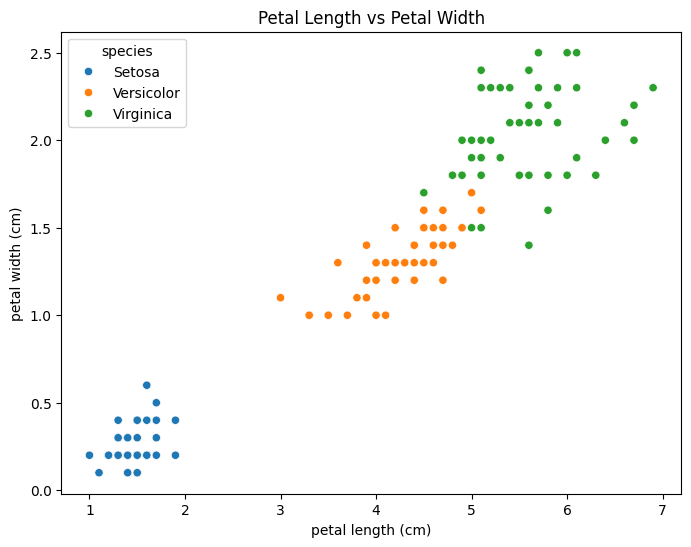

In [10]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species"
)

plt.title("Petal Length vs Petal Width")
plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier

X = df.drop("species", axis=1)
y = iris.target

model = RandomForestClassifier(random_state=42)

model.fit(X, y)

RandomForestClassifier(random_state=42)

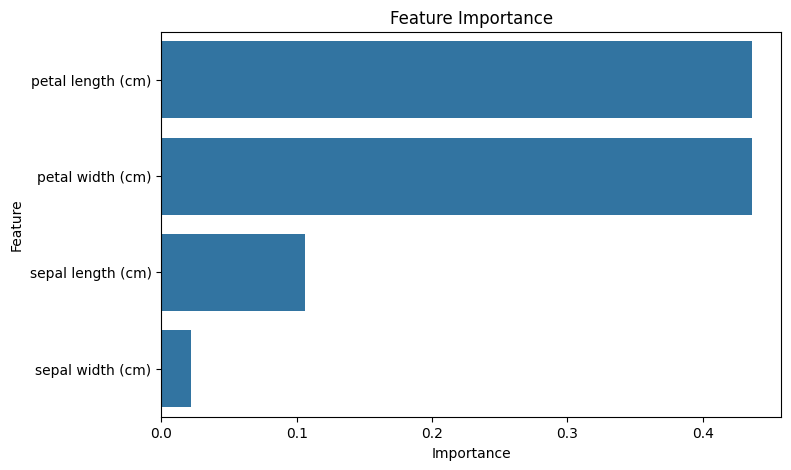

In [15]:
importance = pd.DataFrame({
"Feature": X.columns,
"Importance": model.feature_importances_
})
importance = importance.sort_values(
by="Importance",
ascending=False
)
plt.figure(figsize=(8,5))
sns.barplot(
data=importance,
x="Importance",
y="Feature"
)
plt.title("Feature Importance")
plt.show()

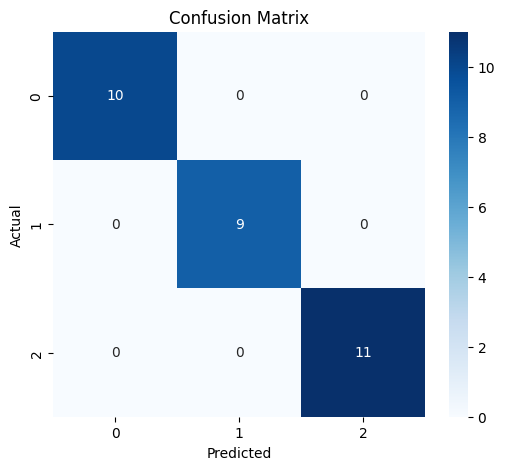

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.2,
random_state=42
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(6,5))
sns.heatmap(
cm,
annot=True,
fmt="d",
cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()